In [2]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from itertools import product as iproduct

In [3]:
Q = np.zeros([3,3])
Q[2,2]=1
Q=qt.Qobj(Q)
P=1-Q
print(P,Q)

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


In [4]:
# ---------------------------------------------------------------------------
# 1.  Embedded Pauli matrices in a d-dimensional space
# ---------------------------------------------------------------------------

def embedded_pauli(alpha: str, a: int, b: int, d: int = 3) -> qt.Qobj:
    """
    Return the Pauli-like matrix sigma^alpha_{(a,b)} embedded in a
    d-dimensional (qutrit) Hilbert space.

    The matrix acts on the 2-dimensional subspace spanned by levels |a> and
    |b> (a != b) exactly as the standard Pauli matrix sigma^alpha, and as
    the identity on all other levels.

    Parameters
    ----------
    alpha : str
        One of 'x', 'y', 'z'.
    a, b : int
        Level indices (0 <= a, b < d, a != b).
    d : int
        Dimension of the local Hilbert space (default 3 for qutrits).

    Returns
    -------
    qt.Qobj
        A (d x d) Qobj representing the embedded Pauli operator.
    """
    if a == b:
        raise ValueError("Level indices a and b must be different.")
    if not (0 <= a < d and 0 <= b < d):
        raise ValueError(f"Level indices must be in [0, {d-1}].")
    if alpha not in ('x', 'y', 'z', 'p-', 'p+'):
        raise ValueError("alpha must be 'x', 'y', 'z', 'p-' or 'p+'.")

    # Start from the identity in d dimensions
    #mat = np.eye(d, dtype=complex)
    mat = np.zeros([d,d], dtype=complex)

    # Overwrite the 2x2 block {a,b} with the chosen Pauli
    # We adopt the convention: a <-> |0>, b <-> |1> in the subspace
    if alpha == 'x':
        mat[a, a] = 0.0;  mat[a, b] = 1.0
        mat[b, a] = 1.0;  mat[b, b] = 0.0
    elif alpha == 'y':
        mat[a, a] = 0.0;  mat[a, b] = -1j
        mat[b, a] =  1j;  mat[b, b] = 0.0
    elif alpha == 'z':
        mat[a, a] = 1.0;  mat[a, b] = 0.0
        mat[b, a] = 0.0;  mat[b, b] = -1.0
    elif alpha == 'p-':
        mat[a, a] = 0.0;  mat[a, b] = 0.0
        mat[b, a] = 0.0;  mat[b, b] = 1.0
    elif alpha == 'p+':
        mat[a, a] = 1.0;  mat[a, b] = 0.0
        mat[b, a] = 0.0;  mat[b, b] = 0.0

    return qt.Qobj(mat, dims=[[d], [d]])

# ---------------------------------------------------------------------------
# 2.  Embed a local operator on site j in the full N-site Hilbert space
# ---------------------------------------------------------------------------

def embed_on_site(op: qt.Qobj, j: int, N: int, d: int = 3) -> qt.Qobj:
    """
    Embed a single-site operator on site j in the full N-qutrit Hilbert space.

    Returns:  I ⊗ ... ⊗ op ⊗ ... ⊗ I
              (op sits at position j, zero-indexed)

    Parameters
    ----------
    op : qt.Qobj
        Local (d x d) operator.
    j : int
        Site index (0-indexed).
    N : int
        Total number of sites.
    d : int
        Local Hilbert space dimension.
    """
    if not (0 <= j < N):
        raise ValueError(f"Site index j={j} out of range [0, {N-1}].")

    ops = [qt.qeye(d)] * N
    ops[j] = op
    return qt.tensor(ops)

# ---------------------------------------------------------------------------
# 3.  Embed a two-body operator on a bond (j, k) in the full Hilbert space
# ---------------------------------------------------------------------------

def embed_on_bond(op1: qt.Qobj, op2: qt.Qobj,
                  j: int, k: int, N: int, d: int = 3) -> qt.Qobj:
    """
    Embed the tensor product op1_j ⊗ op2_k in the full N-qutrit Hilbert space.

    Parameters
    ----------
    op1, op2 : qt.Qobj
        Local (d x d) operators for sites j and k respectively.
    j, k : int
        Site indices (0-indexed, must be distinct).
    N : int
        Total number of sites.
    d : int
        Local Hilbert space dimension.
    """
    if j == k:
        raise ValueError("Sites j and k must be distinct for a two-body term.")
    if not (0 <= j < N and 0 <= k < N):
        raise ValueError(f"Site indices out of range [0, {N-1}].")

    ops = [qt.qeye(d)] * N
    ops[j] = op1
    ops[k] = op2
    return qt.tensor(ops)

In [5]:
# ---------------------------------------------------------------------------
# 4.  Main Hamiltonian builder
# ---------------------------------------------------------------------------

def build_hamiltonian(
    N: int,
    single_body_terms: list,
    two_body_terms: list,
    boundary: str = 'OBC',
    d: int = 3
) -> qt.Qobj:
    """
    Build the full many-body Hamiltonian for a chain of N qutrits.

    Parameters
    ----------
    N : int
        Number of qutrits.

    single_body_terms : list of [coeff, (alpha, a, b), j]
        Each entry specifies a single-site term:
            coeff  : real float, the coupling constant (uniform across sites
                     if j is None, else applied only to site j)
            (alpha, a, b) : operator specification (see embedded_pauli)
            j      : int site index, OR None to apply to all sites

        Examples:
            [1.0, ('z', 0, 1), None]   ->  sum_j sigma^z_{j,(0,1)}
            [0.5, ('x', 1, 2), 3]      ->  0.5 * sigma^x_{3,(1,2)}

    two_body_terms : list of [coeff, (alpha1, a1, b1), (alpha2, a2, b2)]
        Each entry specifies a nearest-neighbour two-body term applied to
        every bond (j, j+1):
            coeff          : real float
            (alpha1,a1,b1) : operator on the left site j
            (alpha2,a2,b2) : operator on the right site j+1

        Examples:
            [1.0, ('x',0,1), ('x',0,1)]  -> sum_j sigma^x_{j} * sigma^x_{j+1}

    boundary : str
        'OBC' (open boundary conditions) or 'PBC' (periodic).

    d : int
        Local Hilbert space dimension (default 3 for qutrits).

    Returns
    -------
    qt.Qobj
        The full Hamiltonian as a (d^N x d^N) Qobj.
    """
    if N < 1:
        raise ValueError("Need at least N=1 qutrit.")
    if boundary not in ('OBC', 'PBC'):
        raise ValueError("boundary must be 'OBC' or 'PBC'.")

    # Hilbert space dimensions list  [d, d, ..., d]
    dims = [[d] * N, [d] * N]
    H = qt.Qobj(np.zeros((d**N, d**N), dtype=complex), dims=dims)

    # --- Single-body terms ---
    for term in single_body_terms:
        coeff, op_spec, site = term
        alpha, a, b = op_spec
        local_op = embedded_pauli(alpha, a, b, d)

        if site is None:
            # Apply uniformly to every site
            for j in range(N):
                H += coeff * embed_on_site(local_op, j, N, d)
        else:
            H += coeff * embed_on_site(local_op, site, N, d)

    # --- Two-body nearest-neighbour terms ---
    # Determine the list of bonds
    if boundary == 'OBC':
        bonds = [(j, j + 1) for j in range(N - 1)]
    else:  # PBC
        bonds = [(j, (j + 1) % N) for j in range(N)]

    for term in two_body_terms:
        coeff, op_spec1, op_spec2 = term
        alpha1, a1, b1 = op_spec1
        alpha2, a2, b2 = op_spec2
        local_op1 = embedded_pauli(alpha1, a1, b1, d)
        local_op2 = embedded_pauli(alpha2, a2, b2, d)

        for j, k in bonds:
            H += coeff * embed_on_bond(local_op1, local_op2, j, k, N, d)

    # Enforce Hermiticity (remove floating-point asymmetries)
    #H = (H + H.dag()) / 2.0
    return H

In [144]:
def project_measurements(psi: qt.Qobj, N: int, proj: qt.Qobj, sites=None, force_proj=False) -> qt.Qobj:
    """
    Perform sequential projective measurements on a many-body state.

    At each site j in `sites`, the local projector `proj` (or its complement
    qt.qeye(3) - proj) is applied with the correct Born-rule probability,
    computed on the *current* (already-collapsed) state.

    Parameters
    ----------
    psi : qt.Qobj
        The initial many-body pure state (ket).
    N : int
        Number of qutrits.
    proj : qt.Qobj
        Local (3x3) projector P satisfying P^2 = P, P = P†.
    sites : list of int, optional
        Sites to measure. Defaults to all sites [0, 1, ..., N-1].

    Returns
    -------
    qt.Qobj
        The normalised post-measurement state.
    """
    if sites is None:
        sites = list(range(N))

    comp_proj = qt.qeye(3) - proj  # complementary projector (I - P)

    for j in sites:
        # Embed projectors in the full Hilbert space
        P_emb  = embed_on_site(proj,      j, N)
        cP_emb = embed_on_site(comp_proj, j, N)

        # Born-rule probability for outcome "proj" on the *current* state
        prob = qt.expect(P_emb, psi)          # real, in [0, 1] for a projector
        prob = float(np.clip(prob.real, 0, 1))

        # Randomly select outcome
        if force_proj:
            psi = P_emb * psi
        else:    
            if np.random.rand() <= prob:
                psi = P_emb * psi
            else:
                psi = cP_emb * psi
        reduced_norm = psi.norm()
        psi = psi.unit()   # normalise after each collapse

    return psi, reduced_norm


from dataclasses import dataclass as _dataclass
import warnings as _warnings
 
@_dataclass
class StationaryResult:
    """
    Output of nh_stationary_states().
 
    Attributes
    ----------
    steady_eigenvalue : complex
        The eigenvalue with the least-negative imaginary part (the
        'most stationary' eigenvalue).
    steady_states : list of qt.Qobj
        Right eigenvectors corresponding to steady_eigenvalue, each
        normalised to unit Euclidean norm.
    degeneracy : int
        Number of eigenvalues whose Im part is within `tol` of
        Im(steady_eigenvalue).  This is the dimension of the steady-state
        manifold as detected by Im(λ) alone.
    entanglement_entropies : list of float
        Half-chain entanglement entropy S = -Tr(rho_A ln rho_A) for each
        state in steady_states.  Computed via SVD of the coefficient
        tensor reshaped across the chosen bipartition.
    all_eigenvalues : np.ndarray
        Full spectrum (complex) sorted by Im(λ) descending (least negative
        first).
    """
    steady_eigenvalue:      complex
    steady_states:          list
    degeneracy:             int
    entanglement_entropies: list
    all_eigenvalues:        np.ndarray
 
 
def nh_stationary_states(
    H:   qt.Qobj,
    N:   int,
    cut: int   = None,
    tol: float = 1e-6,
    d:   int   = 3,
) -> StationaryResult:
    """
    Find the stationary right eigenstates of a non-Hermitian Hamiltonian.
 
    'Stationary' means the right eigenvectors whose eigenvalue has the
    *least-negative* imaginary part — i.e. the slowest-decaying sector
    under the dynamics generated by H.
 
    Uses QuTiP-native methods throughout:
        - Qobj.eigenstates()  for diagonalisation
        - Qobj.ptrace()       for the reduced density matrix of subsystem A
        - qt.entropy_vn()     for the Von Neumann entropy
 
    Note: Qobj.eigenstates() forces a non-Hermitian diagonalisation when
    the Qobj is not flagged as Hermitian.  We explicitly clear that flag
    via a copy to be safe.
 
    Parameters
    ----------
    H : qt.Qobj
        Non-Hermitian Hamiltonian (square matrix operator).
    N : int
        Number of qudits.
    cut : int, optional
        Bipartition cut: subsystem A = sites [0..cut-1], B = [cut..N-1].
        Defaults to N // 2  (half-chain).
    tol : float, optional
        Two eigenvalues are considered degenerate if
        |Im(λ_i) - Im(λ_j)| < tol.  Default 1e-6.
    d : int, optional
        Local Hilbert space dimension (default 3).
 
    Returns
    -------
    StationaryResult
 
    Warnings
    --------
    UserWarning
        Raised if any eigenvalue has Im(λ) > tol, signalling an
        unphysical growing mode.
    """
    if cut is None:
        cut = N // 2
    if not (1 <= cut <= N - 1):
        raise ValueError(f"cut={cut} must satisfy 1 <= cut <= N-1={N-1}.")
 
    # Force QuTiP to treat H as non-Hermitian regardless of numerical noise
    H_nh = H.copy()
    H_nh.isherm = False
 
    # --- diagonalise: eigenstates() returns (evals, [evecs]) ----------------
    # Right eigenvectors only (QuTiP returns right evecs for non-Hermitian)
    eigenvalues, eigenstates = H_nh.eigenstates()   # evals sorted by Re(λ)
 
    # Re-sort by Im(λ) descending: index 0 = least negative = most stationary
    sort_idx    = np.argsort(eigenvalues.imag)[::-1]
    eigenvalues = eigenvalues[sort_idx]
    eigenstates = [eigenstates[i] for i in sort_idx]
 
    # --- warn about unphysical growing modes --------------------------------
    growing_im = eigenvalues[eigenvalues.imag > tol].imag
    if len(growing_im):
        _warnings.warn(
            f"{len(growing_im)} eigenvalue(s) have Im(λ) > tol={tol}: "
            f"unphysical growing modes detected.\n"
            f"  Im(λ) values: {np.round(growing_im, 8)}",
            UserWarning,
            stacklevel=2,
        )
 
    # --- steady-state manifold ----------------------------------------------
    steady_im  = eigenvalues[0].imag
    degen_mask = np.abs(eigenvalues.imag - steady_im) < tol
    degeneracy = int(degen_mask.sum())
 
    steady_states = [eigenstates[i] for i, m in enumerate(degen_mask) if m]
 
    # --- entanglement entropy via ptrace + entropy_vn -----------------------
    # ptrace(keep) traces out all sites *except* those in `keep`.
    # We keep subsystem A = [0..cut-1].
    keep_A    = list(range(cut))
    entropies = []
    for psi in steady_states:
        # Normalise with Euclidean norm (right evecs are not orthonormal)
        psi_norm = psi.unit()
        # ptrace returns the reduced density matrix rho_A
        rho_A = psi_norm.ptrace(keep_A)
        # qt.entropy_vn computes S = -Tr(rho log rho), base=e by default
        entropies.append(qt.entropy_vn(rho_A))
 
    return StationaryResult(
        steady_eigenvalue      = eigenvalues[0],
        steady_states          = steady_states,
        degeneracy             = degeneracy,
        entanglement_entropies = entropies,
        all_eigenvalues        = eigenvalues,
    )
 

In [14]:
# ---------------------------------------------------------------------------
# 6.  Measurement-interrupted unitary evolution
# ---------------------------------------------------------------------------

from dataclasses import dataclass

@dataclass
class EvoResult:
    """
    Container for time_evo output, mirroring the feel of QuTiP Result objects.

    Attributes
    ----------
    times : np.ndarray
        The time points supplied by the user.
    states : list of qt.Qobj
        State after unitary evolution AND projective measurement at each time.
    expect : list of np.ndarray
        expect[k][i] = <e_ops[k]> at times[i]  (evaluated after measurement).
    measurement_outcomes : list of qt.Qobj or None
        Collapsed (normalised) state at each measurement step; None at step 0
        and at steps where no measurement was requested.
    """
    times:                np.ndarray
    states:               list
    expect:               list
    measurement_outcomes: list


def time_evo(
    H:              qt.Qobj,
    psi0:           qt.Qobj,
    times,
    proj:           qt.Qobj,
    N:              int,
    measured_sites: list = None,
    e_ops:          list = None,
    force_proj:     bool = False,
    options:        dict = None,
) -> EvoResult:
    """
    Unitary evolution interrupted by projective measurements at each time step.

    The protocol at every interval [times[i], times[i+1]] is:
        1. Evolve unitarily:  psi -> exp(-i H dt) |psi>
        2. Apply projective measurements on `measured_sites` via
           project_measurements() (sequential Born-rule collapses).
        3. Record the resulting state and expectation values.
        TODO: if dt is unifrom, only one propagator is needed.

    Parameters
    ----------
    H : qt.Qobj
        Time-independent Hamiltonian (hbar = 1 units).
    psi0 : qt.Qobj
        Initial pure state (ket).
    times : array-like
        Monotonically increasing time points. The first entry is the initial
        time; evolution and measurements begin from the second entry onward.
    proj : qt.Qobj
        Local (d x d) projector applied at every measured site.
    N : int
        Number of qutrits.
    measured_sites : list of int, optional
        Sites on which to perform projective measurements after each unitary
        step. Pass [] or None to skip measurements (pure unitary evolution).
    e_ops : list of qt.Qobj, optional
        Global operators whose expectation values are tracked at every time
        point (evaluated *after* measurement).
    options : dict, optional
        Fine-tuning knobs:
            'progress' : bool  – print progress at each step (default True).

    Returns
    -------
    EvoResult
        .times                – input time array as np.ndarray
        .states               – list of qt.Qobj, one per time point
        .expect               – list of np.ndarray, one per e_ops entry
        .measurement_outcomes – list of qt.Qobj or None, one per time point
    """
    # --- defaults -----------------------------------------------------------
    times          = np.asarray(times, dtype=float)
    measured_sites = measured_sites or []
    e_ops          = e_ops or []
    opts           = {'progress': True, 'uniform_dt': True}
    if options:
        opts.update(options)

    n_steps = len(times)

    # --- output containers --------------------------------------------------
    states               = [None] * n_steps
    measurement_outcomes = [None] * n_steps
    expect_vals          = [np.zeros(n_steps, dtype=float) for _ in e_ops]

    def _record(i, psi):
        states[i] = psi
        for k, op in enumerate(e_ops):
            expect_vals[k][i] = qt.expect(op, psi)
    # --- check hermiticity of observables
    for e_ind, e_op in enumerate(e_ops):
        if not e_op.isherm :
            print(f"WARNING: observable e_ops[{e_ind}] is not hermitian")
            
    # --- step 0: initial state (no evolution, no measurement) ---------------
    psi = psi0.unit()
    _record(0, psi)

    # --- pre-compute unitary propagators for each interval ------------------
    # qt.propagator builds U = exp(-i H dt) via eigendecomposition of H,
    # which is efficient for a time-independent Hamiltonian.
    if opts['progress']:
        print(f"Pre-computing {n_steps - 1} propagator(s)...")
    
    if opts['uniform_dt']:
        dt = times[1]-times[0]
        U = qt.propagator(H, dt)
    else:
        propagators = []
        for i in range(n_steps - 1):
            dt = times[i + 1] - times[i]
            if dt < 0:
                raise ValueError(
                    f"times must be monotonically increasing "
                    f"(times[{i+1}]={times[i+1]:.4g} < times[{i}]={times[i]:.4g})."
                )
            propagators.append(qt.propagator(H, dt))

    # --- main loop ----------------------------------------------------------
    for i, t in enumerate(times[1:]):
        step = i + 1

        # 1. Unitary evolution
        if not opts['uniform_dt']:
            U = propagators[i]
        
        psi = (U * psi).unit()

        # 2. Projective measurements
        if measured_sites:
            psi, reduced_norm = project_measurements(psi, N, proj, sites=measured_sites,force_proj=force_proj)
            measurement_outcomes[step] = reduced_norm

        # 3. Record
        _record(step, psi)

        if opts['progress']:
            ev_str = (f"  |  <e_ops[0]> = {expect_vals[0][step]:.4f}"
                      if e_ops else "")
            print(f"  step {step:>4d}/{n_steps-1}  |  t = {times[step]:.4g}{ev_str}")

    # --- package and return -------------------------------------------------
    return EvoResult(
        times                = times,
        states               = states,
        expect               = expect_vals,
        measurement_outcomes = measurement_outcomes,
    )

In [118]:
def poisson_times(t_f : float, rate:float):
    times=[0.0]
    while times[-1]< t_f:
        r = np.random.exponential(scale = 1/rate)
        times.append(times[-1]+r)
    else: times[-1] = t_f

    return np.array(times)


def get_entanglement(states,sites):
    vnEntropy=[]
    for state in states:
        rdm = qt.ptrace(state,sites)
        eHeigs = rdm.eigenenergies()
        vnEntropy.append(-sum(eHeigs*np.log(eHeigs+1e-15)))
    return vnEntropy

In [136]:
N=2
h, J, Omega= 1,5.3, 2*np.sqrt(2)
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1])
psi0_eff = qt.basis([2]*N,n=[0,1])

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

effective paramters: lambda_1=0.00-0.20j, lambda_2=0.00-0.70j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.]


In [137]:
res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

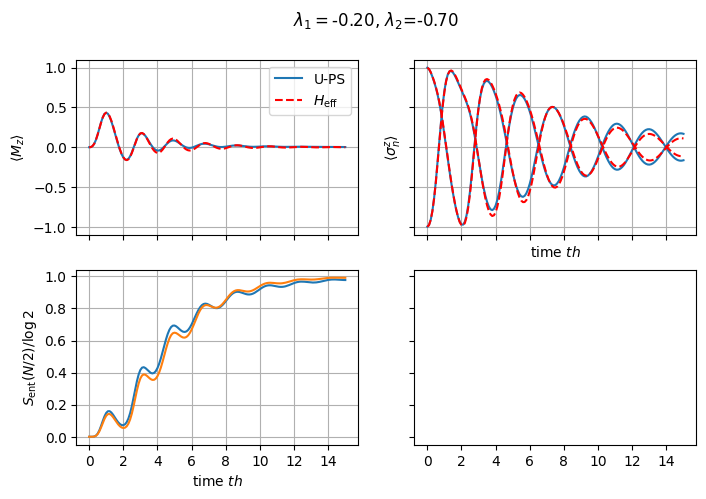

In [142]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,res.expect[0],label='U-PS',c='C0')
ax[0,1].plot(tvec,res.expect[1],label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,res2.expect[0],'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,res2.expect[1],'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[0])/np.log(2))
ax[1,0].plot(tvec,get_entanglement(res2.states,[0])/np.log(2))
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log 2$')

#ax[1,1].plot(tvec[1:],np.cumsum(1-np.array(res.measurement_outcomes[1:]))) 
'''
plt.plot(tvec,res.expect[0])
plt.plot(tvec,res.expect[1])

plt.plot(trand,res_rand.expect[0],'-.')
plt.plot(trand,res_rand.expect[1],'-.')

plt.plot(tvec,res2.expect[0],'--')
plt.plot(tvec,res2.expect[1],'--')
plt.xlabel(r"time $t h_x$")
'''
fig.savefig('N2_entangled.pdf',bbox_inches='tight')

In [132]:
N=2
h, J, Omega= 1,7.2, 5.3
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1])
psi0_eff = qt.basis([2]*N,n=[0,1])

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=0.00-0.70j, lambda_2=0.00-1.30j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.]


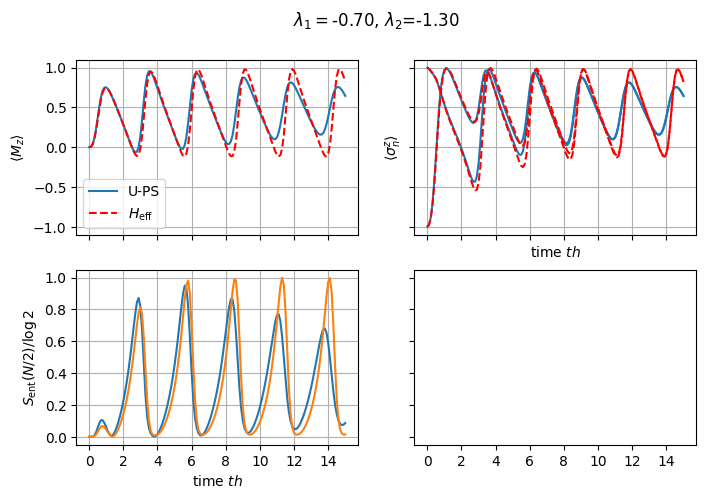

In [133]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,res.expect[0],label='U-PS',c='C0')
ax[0,1].plot(tvec,res.expect[1],label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,res2.expect[0],'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,res2.expect[1],'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[0])/np.log(2))
ax[1,0].plot(tvec,get_entanglement(res2.states,[0])/np.log(2))
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log 2$')
fig.savefig('N2_oscillatory.pdf',bbox_inches='tight')

In [134]:
N=2
h, J, Omega= 1,3.5, 5.1*np.sqrt(2)
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1])
psi0_eff = qt.basis([2]*N,n=[0,1])

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=0.00-1.30j, lambda_2=0.00-0.31j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.]


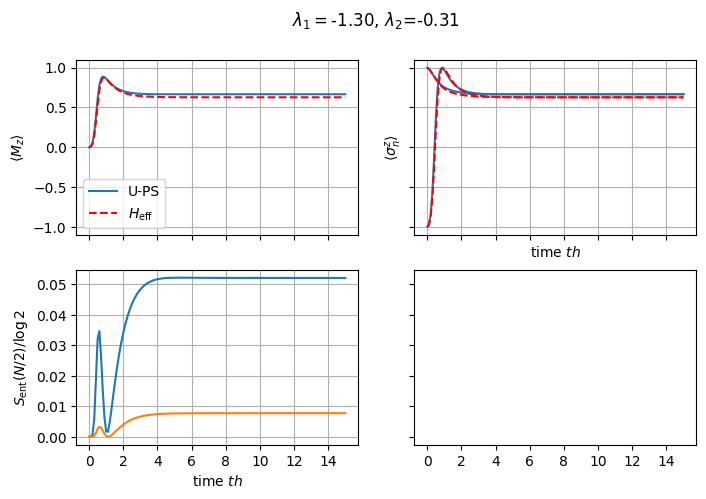

In [135]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,res.expect[0],label='U-PS',c='C0')
ax[0,1].plot(tvec,res.expect[1],label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,res2.expect[0],'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,res2.expect[1],'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[0])/np.log(2))
ax[1,0].plot(tvec,get_entanglement(res2.states,[0])/np.log(2))
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log 2$')

fig.savefig('N2_separable.pdf',bbox_inches='tight')

In [156]:
N = 2
h=1
lambda1_list=np.linspace(0.01,1.5,100)
lambda2_list=np.linspace(0.01,1.5,100)
gs_multiplicity = []
gs_entropy = []
for lam1 in lambda1_list:
    for lam2 in lambda2_list:
        heff, lambda1, lambda2 = h, -1j*lam1, -1j*lam2
        #print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
        single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
        two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
        H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
        res = nh_stationary_states(H_qeff,N, tol=1e-8,d=2)
        gs_multiplicity.append(res.degeneracy)
        gs_entropy.append(np.array(res.entanglement_entropies).mean())        

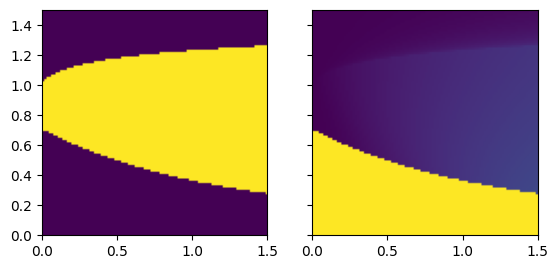

In [163]:
fig, ax = plt.subplots(ncols=2,sharex=True, sharey=True)
ax[0].imshow(np.array(gs_multiplicity).reshape([100,100]),origin='lower', extent=[0,1.5,0,1.5])
ax[1].imshow(np.array(gs_entropy).reshape([100,100]),origin='lower', extent=[0,1.5,0,1.5])

In [ ]:
plt.imshow()